# Problem 1

In [112]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

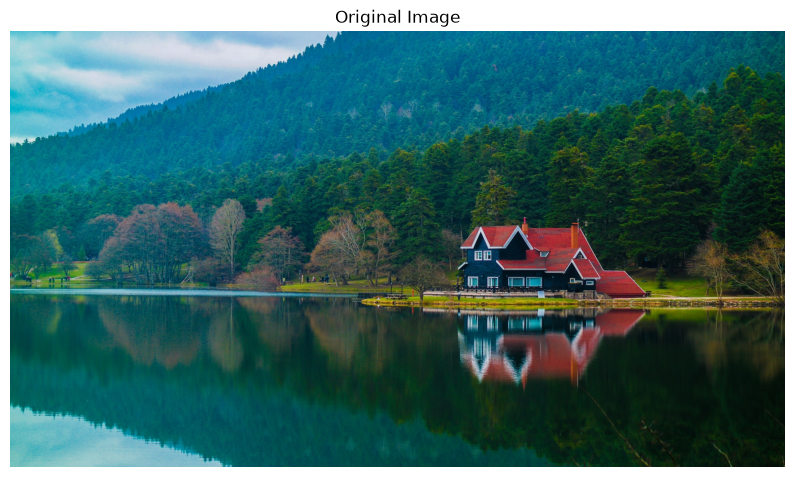

In [113]:
org_image = cv2.imread("images/image.jpg")
# cv2.imshow("Original Image", org_image)

# matplotlib needs RGB image but openCV default creates image as BGR.
plt.figure(figsize=(10,6))
plt.imshow(cv2.cvtColor(org_image, cv2.COLOR_BGR2RGB))
plt.title("Original Image")
plt.axis("off")
plt.show()

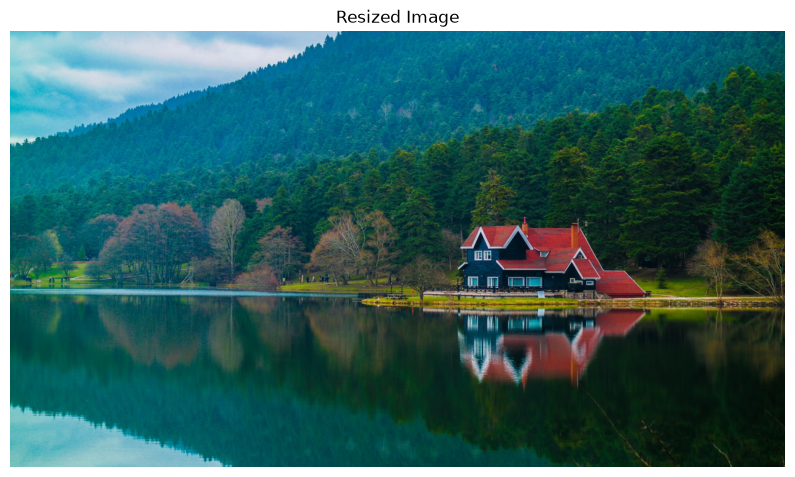

In [114]:
# resize can be applied with directly new height and width values or scale factor. scale factor is used.
# interpolation is optional, inter_area, inter_linear, inter_cubic, inter_nearst are options.
# inter_area is used for downscaling.
resized_image = cv2.resize(org_image, None, fx=0.75, fy=0.75, interpolation=cv2.INTER_AREA)
cv2.imwrite("images/resized_image.png", resized_image)

plt.figure(figsize=(10,6))
plt.imshow(cv2.cvtColor(resized_image, cv2.COLOR_BGR2RGB))
plt.title("Resized Image")
plt.axis("off")
plt.show()

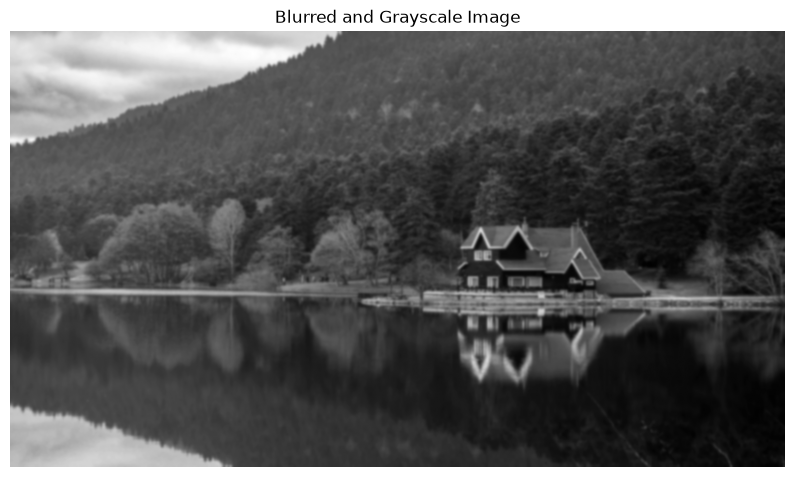

In [115]:
grayscale_resized_image = cv2.cvtColor(resized_image, cv2.COLOR_BGR2GRAY)

# second input is kernel size. (0, 0) makes kernel size based on sigma.
blurred_image = cv2.GaussianBlur(grayscale_resized_image, (0, 0), sigmaX=2)

# matplotlib render pixel intensities as gray when cmap="gray" used.
plt.figure(figsize=(10,6))
plt.imshow(blurred_image, cmap="gray")
plt.title("Blurred and Grayscale Image")
plt.axis("off")
plt.show()

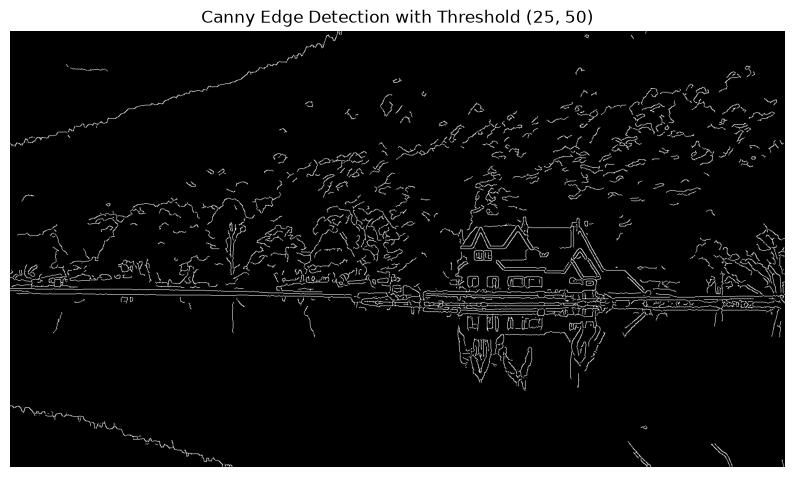

In [116]:
# low and high threshold values.
edges = cv2.Canny(blurred_image, 25, 50)

plt.figure(figsize=(10,6))
plt.imshow(edges, cmap="gray")
plt.title("Canny Edge Detection with Threshold (25, 50)")
plt.axis("off")
plt.show()

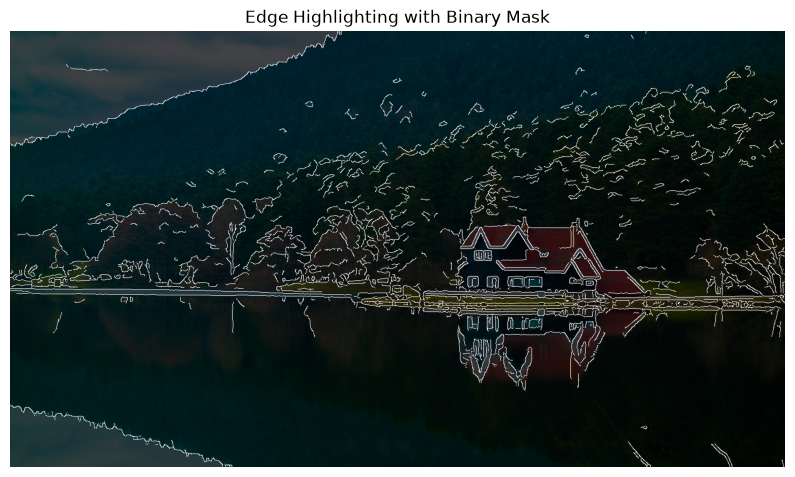

In [ ]:
# using resized image because sizes needs to match. intensities dimmed with factor 0.3.
# also converting floats after multipication to the 8 bit integers again.
dimmed_image = (resized_image * 0.3).astype(np.uint8)

# first way.
'''
for i, row in enumerate(dimmed_image):
    for j, pixel in enumerate(row):
        if(edges[i][j] > 0):
            dimmed_image[i][j] = [255, 255, 255]
'''

# second way with numpy boolean.
dimmed_image[edges > 0] = [255, 255, 255]

plt.figure(figsize=(10, 6))
plt.imshow(cv2.cvtColor(dimmed_image, cv2.COLOR_BGR2RGB))
plt.title("Edge Highlighting with Binary Mask")
plt.axis("off")
plt.show()


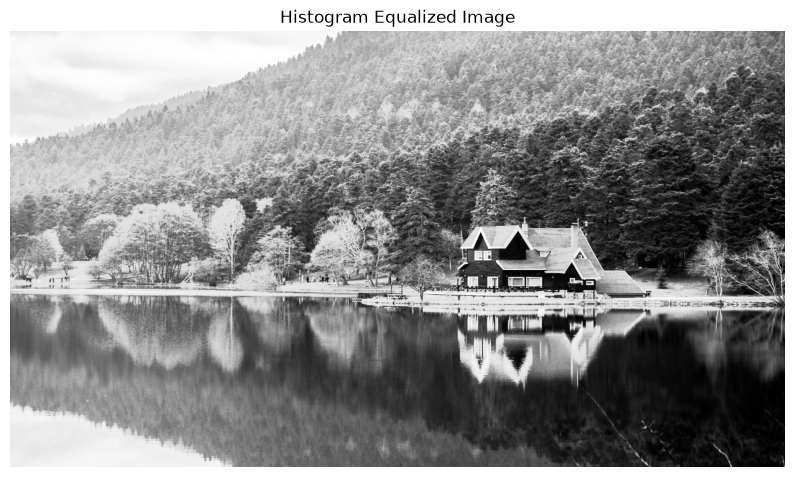

In [ ]:
# histogram
equalized_image = cv2.equalizeHist(grayscale_resized_image)

plt.figure(figsize=(10,6))
plt.imshow(equalized_image, cmap="gray")
plt.title("Histogram Equalized Image")
plt.axis("off")
plt.show()